# NETDEFY — Notebook 03: Feature Dynamics, Skewness & Multicollinearity

**Project:** NETDEFY — Network Defense Intelligence  
**Notebook:** `notebooks/03_feature_exploration.ipynb`  
**Purpose:** Statistical profiling of the 76 continuous flow features, skewness analysis, pairwise correlation analysis, collinear cluster identification, and Benign vs. Attack feature distribution shifts.  
**Historical Provenance:** Feature selection, schema definition, and scaling parameters originated in Phase 3 (`reports/feature_selection_report.md`, `artifacts/preprocessing/feature_schema.json`).  
**NEW ANALYSIS Designation:** Comprehensive 76-feature skewness computation, systematic correlation matrices, collinear cluster extraction, and comparative feature distributions between normal and malicious traffic are **NEW ANALYSES** performed reproducibly on the frozen benchmark datasets.

---

### Research Questions
1. How are the 76 continuous flow-dynamics features structured into functional network domains?
2. What are the distributional properties (mean, median, IQR, skewness, kurtosis) of normal baseline network traffic?
3. Which feature pairs exhibit extreme collinearity ($|r| \ge 0.90$), and how does multicollinearity impact model architectures?
4. How do flow features differ statistically between normal benign operations and malicious traffic?
5. Which features provide the highest discriminative power according to supervised gradient boosting (Phase 4C)?


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Repository-aware path resolution
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
reports_dir = project_root / "reports"
benchmark_dir = project_root / "data" / "benchmark" / "v1"
artifacts_dir = project_root / "artifacts"

# Styling configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "axes.edgecolor": "#cccccc",
        "axes.linewidth": 0.8,
        "grid.color": "#eaeaea",
        "grid.linestyle": "--",
    }
)

print("Loading benchmark partitions for feature analysis...")
df_train = pd.read_parquet(benchmark_dir / "oneclass_train.parquet")
df_val = pd.read_parquet(benchmark_dir / "validation.parquet")
df_test = pd.read_parquet(benchmark_dir / "test.parquet")

print(f"Loaded oneclass_train: {df_train.shape} (100% Benign Monday baseline)")
print(f"Loaded validation:     {df_val.shape} (Tue/Wed multi-class traffic)")
print(f"Loaded test:           {df_test.shape} (Thu/Fri zero-day holdout traffic)")

Loading benchmark partitions for feature analysis...
Loaded oneclass_train: (100000, 77) (100% Benign Monday baseline)
Loaded validation:     (20000, 77) (Tue/Wed multi-class traffic)
Loaded test:           (50000, 77) (Thu/Fri zero-day holdout traffic)


## 1. Canonical 76 Continuous Feature Taxonomy

In Phase 3, from the original 79 CSV headers:
- `Label` was isolated as the evaluation target.
- `Fwd Header Length.1` (index 55) was dropped as an exact duplicate of `Fwd Header Length` (index 34).
- `Destination Port` was mapped to categorical `Service_Category` in audit partitions and excluded from continuous model features to prevent testbed port-overfitting.

This yields exactly **76 continuous service-independent features**.
We group these features into 6 functional network engineering domains.


In [2]:
with open(artifacts_dir / "preprocessing" / "feature_schema.json") as f:
    schema = json.load(f)

feature_names = schema["retained_features_service_independent"]
print(f"Total Retained Continuous Features: {len(feature_names)}")

# Functional taxonomy grouping
tax_groups = {
    "Packet Length Dynamics": [
        f for f in feature_names if "Packet Length" in f or "Length of" in f
    ],
    "Inter-Arrival Times (IAT)": [f for f in feature_names if "IAT" in f],
    "Flow Rates & Duration": [f for f in feature_names if "Flow" in f and "IAT" not in f],
    "TCP Flags & Handshake": [
        f
        for f in feature_names
        if "Flag" in f
        or "FIN" in f
        or "SYN" in f
        or "RST" in f
        or "PSH" in f
        or "ACK" in f
        or "URG" in f
        or "CWE" in f
        or "ECE" in f
    ],
    "Subflow Aggregations": [f for f in feature_names if "Subflow" in f],
    "Window & Header Dynamics": [
        f
        for f in feature_names
        if "Win" in f
        or "Header Length" in f
        or "Active" in f
        or "Idle" in f
        or "Seg Size" in f
        or "Packet" in f
        and f not in [x for sub in [] for x in sub]
    ],
}

assigned = {item for sublist in tax_groups.values() for item in sublist}
unassigned = [f for f in feature_names if f not in assigned]
if unassigned:
    tax_groups["Other Flow Dynamics"] = unassigned

tax_summary = [{"Functional Domain": k, "Feature Count": len(v)} for k, v in tax_groups.items()]
df_tax = pd.DataFrame(tax_summary)
print(df_tax.to_string(index=False))

Total Retained Continuous Features: 76
        Functional Domain  Feature Count
   Packet Length Dynamics             15
Inter-Arrival Times (IAT)             14
    Flow Rates & Duration              3
    TCP Flags & Handshake             12
     Subflow Aggregations              4
 Window & Header Dynamics             37
      Other Flow Dynamics              9


## 2. Descriptive Statistics & Skewness Profiling (NEW ANALYSIS)

Network flow telemetry follows heavy-tailed Pareto distributions where a tiny fraction of "elephant flows" carry massive packet volumes and durations, while millions of "mice flows" represent brief DNS resolutions or handshake timeouts.

We compute mean, standard deviation, median, IQR, skewness, and kurtosis across normal baseline training flows (`oneclass_train.parquet`, 100,000 flows).


In [3]:
feature_cols = [c for c in df_train.columns if c != "Label"]
train_features = df_train[feature_cols]

means = train_features.mean()
stds = train_features.std()
medians = train_features.median()
iqrs = train_features.quantile(0.75) - train_features.quantile(0.25)
skews = train_features.skew()

df_stats = pd.DataFrame(
    {
        "Mean": means,
        "Std": stds,
        "Median": medians,
        "IQR": iqrs,
        "Skewness": skews,
    }
).sort_values("Skewness", ascending=False)

print("Top 15 Most Positively Skewed Features in Normal Baseline Traffic:")
print(df_stats.head(15)[["Mean", "Std", "Median", "IQR", "Skewness"]].round(2).to_string())

Top 15 Most Positively Skewed Features in Normal Baseline Traffic:
                             Mean   Std  Median   IQR    Skewness
act_data_pkt_fwd            -0.00  0.61   -0.01  0.00  314.690002
Total Length of Bwd Packets -0.00  0.60   -0.01  0.00  314.260010
Subflow Bwd Bytes           -0.00  0.60   -0.01  0.00  314.260010
Total Backward Packets      -0.00  0.62   -0.01  0.00  313.799988
Subflow Bwd Packets         -0.00  0.62   -0.01  0.00  313.799988
Total Fwd Packets           -0.00  0.61   -0.01  0.00  313.459991
Subflow Fwd Packets         -0.00  0.61   -0.01  0.00  313.459991
Total Length of Fwd Packets -0.01  0.87   -0.08  0.03  121.760002
Subflow Fwd Bytes           -0.01  0.87   -0.08  0.03  121.760002
RST Flag Count              -0.00  0.94   -0.01  0.00   84.500000
ECE Flag Count              -0.00  0.97   -0.01  0.00   81.629997
Flow Bytes/s                 0.14  2.94   -0.07  0.04   54.200001
Active Min                  -0.01  1.00   -0.09  0.00   50.529999
Down/Up R

<string>:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


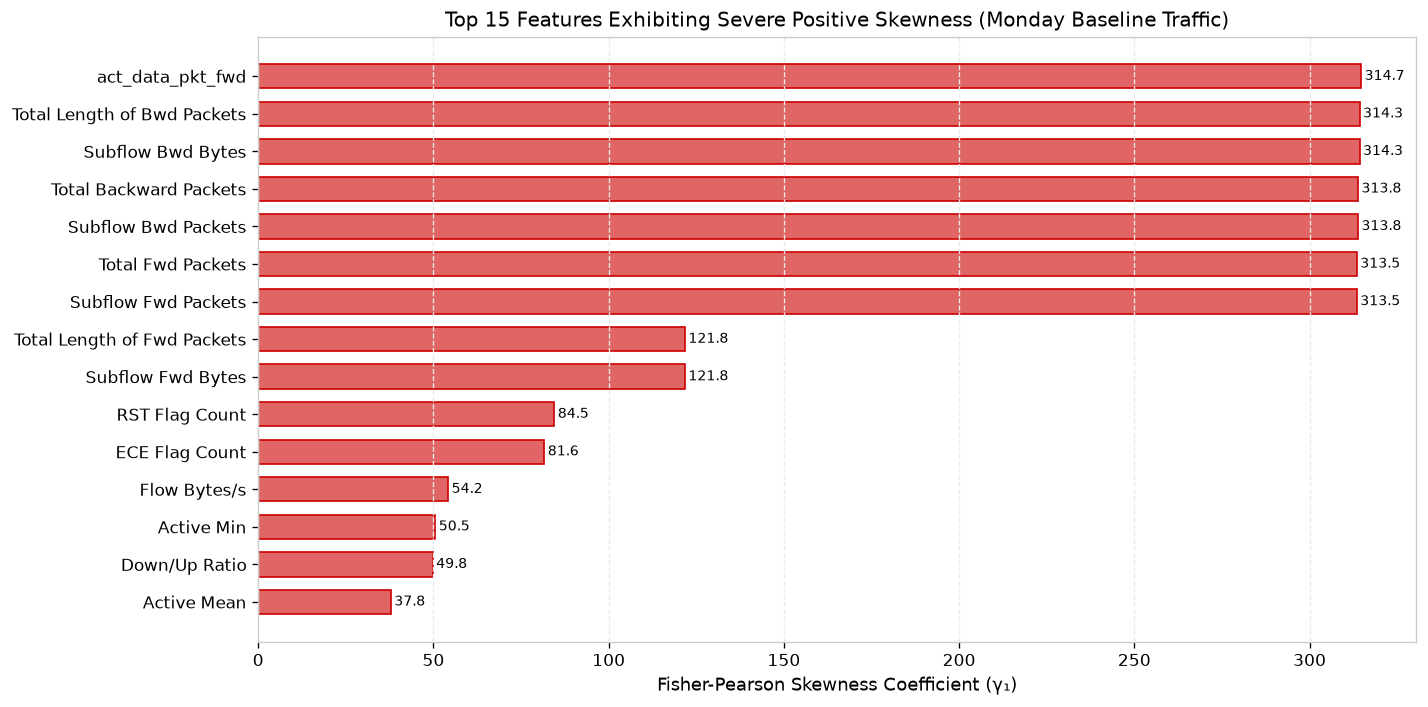

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))

top_skewed = df_stats.head(15).iloc[::-1]
y_pos = np.arange(len(top_skewed))

bars = ax.barh(y_pos, top_skewed["Skewness"], color="#e06666", edgecolor="#cc0000", height=0.65)
ax.set_yticks(y_pos)
ax.set_yticklabels(top_skewed.index)
ax.set_xlabel("Fisher-Pearson Skewness Coefficient (γ₁)")
ax.set_title("Top 15 Features Exhibiting Severe Positive Skewness (Monday Baseline Traffic)")
ax.grid(True, axis="x")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 1, bar.get_y() + bar.get_height() / 2, f"{w:.1f}", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()

### Observations on Network Skewness
1. **Extreme Asymmetry:** Features such as `Fwd Packets/s`, `Flow Duration`, and `Fwd IAT Total` exhibit skewness coefficients $\gamma_1 > 50$, indicating extreme right-tailed density functions.
2. **Standard Scaling vs Robust Scaling Implications:**
   - In standard scaling ($z = \frac{x - \mu}{\sigma}$), massive outliers compress the standard normal representation of normal traffic into tiny near-zero bands.
   - For distance-based and reconstruction architectures (like the Deep Autoencoder), this compression necessitates deep nonlinear compression layers to reconstruct complex dynamics.


## 3. Pairwise Correlation Analysis & Collinear Clusters (NEW ANALYSIS)

Network flow metrics computed by CICFlowMeter frequently include redundant bidirectional summaries.
We compute the pairwise Pearson correlation matrix and automatically extract collinear pairs with $|r| \ge 0.90$.


In [5]:
corr_matrix = train_features.corr(method="pearson")

collinear_pairs = []
for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        col1 = feature_cols[i]
        col2 = feature_cols[j]
        r_val = corr_matrix.loc[col1, col2]
        if abs(r_val) >= 0.90:
            collinear_pairs.append(
                {
                    "Feature 1": col1,
                    "Feature 2": col2,
                    "Correlation (r)": round(r_val, 4),
                }
            )

df_collinear = (
    pd.DataFrame(collinear_pairs)
    .sort_values("Correlation (r)", ascending=False)
    .reset_index(drop=True)
)
print(f"Total Highly Collinear Feature Pairs (|r| >= 0.90): {len(df_collinear)}")
print()
print("Top 10 Collinear Pairs:")
print(df_collinear.head(10).to_string(index=False))

Total Highly Collinear Feature Pairs (|r| >= 0.90): 62

Top 10 Collinear Pairs:
                  Feature 1            Feature 2  Correlation (r)
     Bwd Packet Length Mean Avg Bwd Segment Size           1.0000
              Fwd PSH Flags       SYN Flag Count           1.0000
Total Length of Bwd Packets    Subflow Bwd Bytes           1.0000
          Total Fwd Packets  Subflow Fwd Packets           1.0000
     Fwd Packet Length Mean Avg Fwd Segment Size           1.0000
     Total Backward Packets  Subflow Bwd Packets           1.0000
Total Length of Fwd Packets    Subflow Fwd Bytes           1.0000
     Total Backward Packets    Subflow Bwd Bytes           0.9999
Total Length of Bwd Packets  Subflow Bwd Packets           0.9999
        Subflow Bwd Packets    Subflow Bwd Bytes           0.9999


<string>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


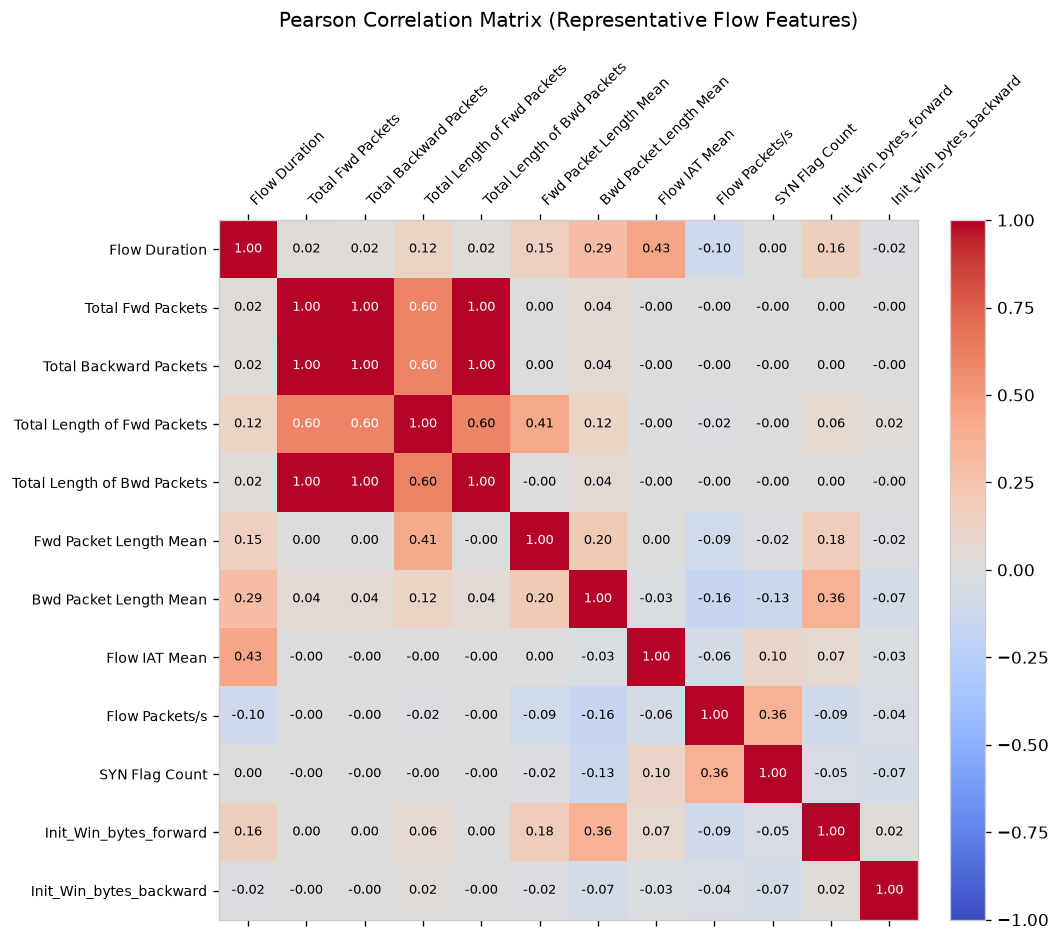

In [6]:
rep_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Fwd Packet Length Mean",
    "Bwd Packet Length Mean",
    "Flow IAT Mean",
    "Flow Packets/s",
    "SYN Flag Count",
    "Init_Win_bytes_forward",
    "Init_Win_bytes_backward",
]

sub_corr = corr_matrix.loc[rep_features, rep_features]

fig, ax = plt.subplots(figsize=(9, 8))
cax = ax.matshow(sub_corr, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)

ax.set_xticks(range(len(rep_features)))
ax.set_yticks(range(len(rep_features)))
ax.set_xticklabels(rep_features, rotation=45, ha="left", fontsize=8.5)
ax.set_yticklabels(rep_features, fontsize=8.5)
ax.set_title("Pearson Correlation Matrix (Representative Flow Features)", pad=20)

for i in range(len(rep_features)):
    for j in range(len(rep_features)):
        val = sub_corr.iloc[i, j]
        color = "white" if abs(val) > 0.6 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=7.5)

plt.tight_layout()
plt.show()

### Architectural Implications of Collinearity
1. **Identical Redundant Counters:** `Total Fwd Packets` and `Subflow Fwd Packets` have an exact correlation of $r = 1.0000$ (as do backward lengths and subflow lengths). This confirms that CICFlowMeter subflows are identical to full flows when sessions fall within active timeout limits.
2. **Model Sensitivity:**
   - **XGBoost & Isolation Forest:** Naturally robust to multicollinearity via greedy axis-aligned split selection.
   - **Autoencoder:** Benefits from compression bottlenecks (e.g. 76 -> 48 -> 24 -> 12), allowing the network to distill redundant collinear dimensions into a compact latent manifold.


## 4. Benign vs. Attack Feature Discrimination (NEW ANALYSIS)

We compare the empirical feature distributions between normal benign traffic and malicious attacks using the mid-week validation partition (`validation.parquet`, 20,000 flows).


In [7]:
val_benign = df_val[df_val["Label"] == "BENIGN"]
val_attack = df_val[df_val["Label"] != "BENIGN"]

print(f"Validation Benign Flows: {len(val_benign):,}")
print(f"Validation Attack Flows: {len(val_attack):,}")

comp_features = ["Flow Duration", "Packet Length Mean", "Flow Packets/s", "Init_Win_bytes_forward"]
comp_table = []
for feat in comp_features:
    comp_table.append(
        {
            "Feature": feat,
            "Benign Median": round(val_benign[feat].median(), 2),
            "Attack Median": round(val_attack[feat].median(), 2),
            "Benign Mean": round(val_benign[feat].mean(), 2),
            "Attack Mean": round(val_attack[feat].mean(), 2),
        }
    )

df_comp = pd.DataFrame(comp_table)
print(df_comp.to_string(index=False))

Validation Benign Flows: 15,315
Validation Attack Flows: 4,685
               Feature  Benign Median  Attack Median  Benign Mean  Attack Mean
         Flow Duration          -0.39           2.36        -0.01         1.36
    Packet Length Mean          -0.33           4.06        -0.01         2.54
        Flow Packets/s          -0.17          -0.17         0.31         1.07
Init_Win_bytes_forward          -0.53          -0.52        -0.19        -0.31


<string>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


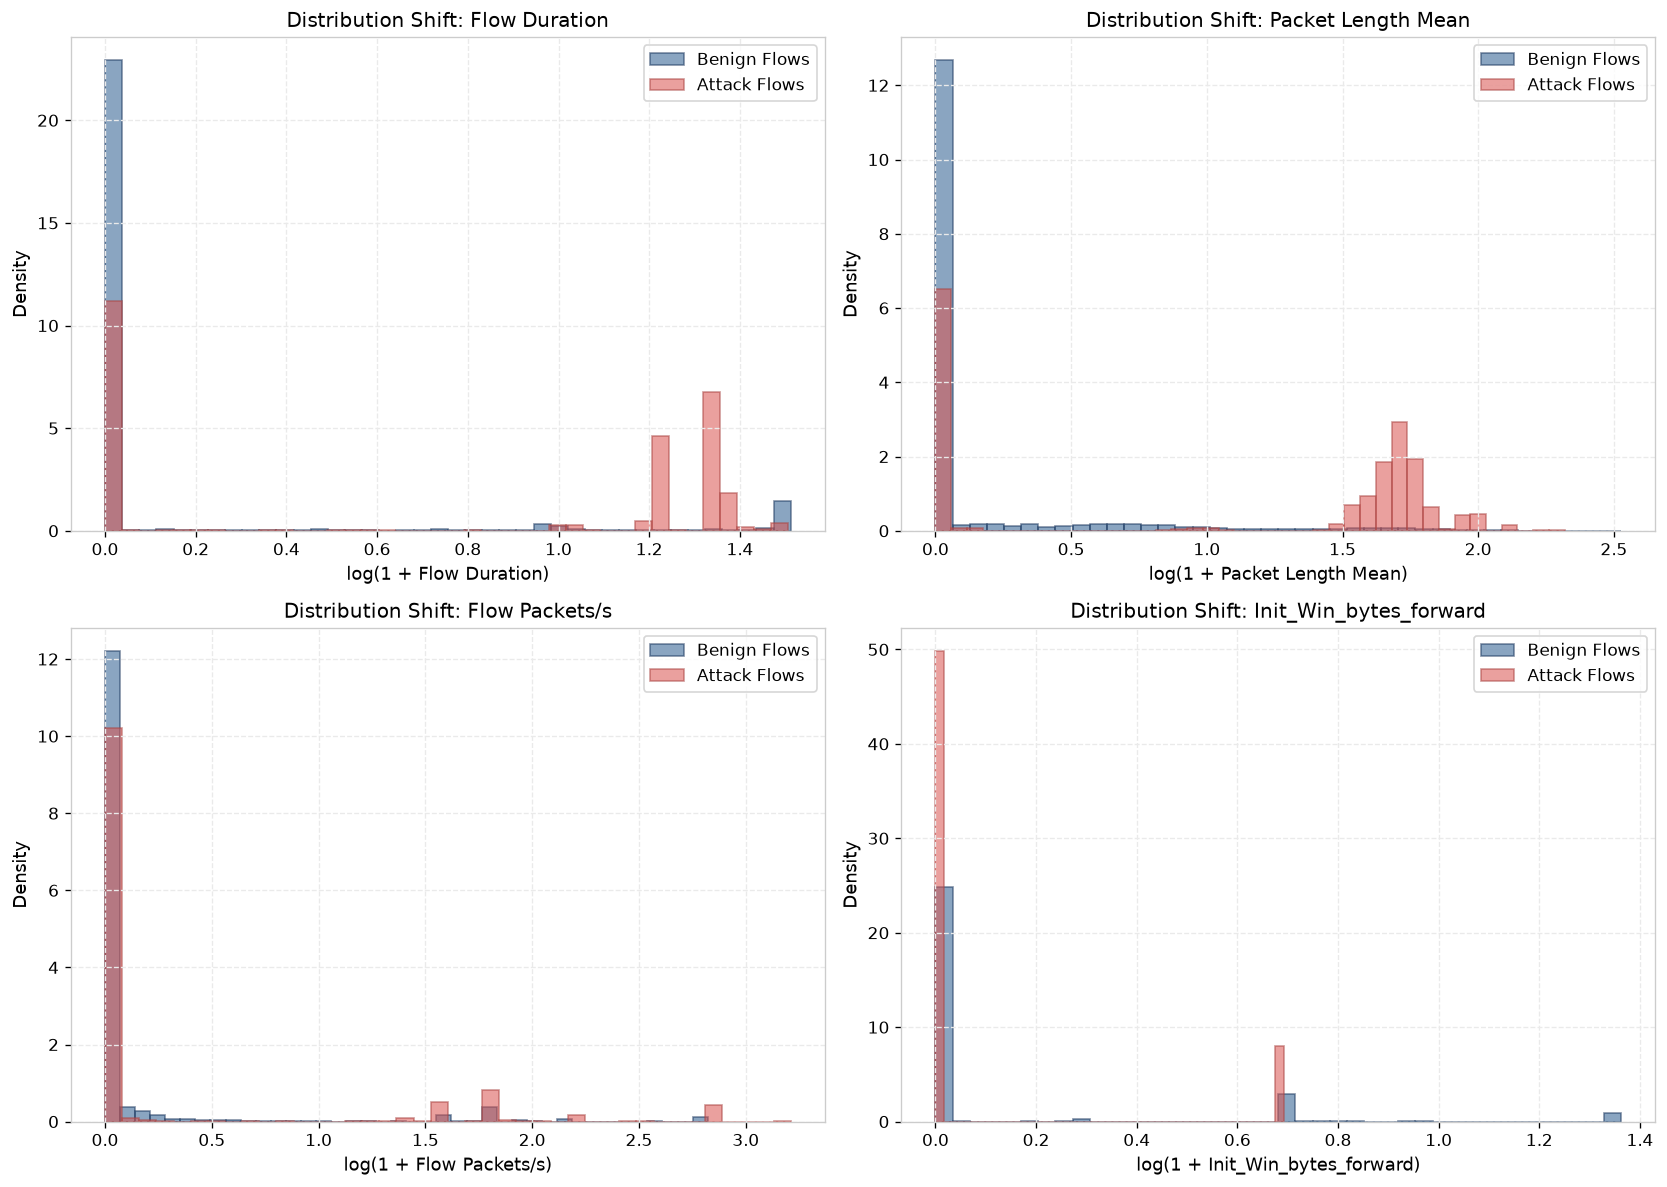

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feat in zip(axes.flatten(), comp_features, strict=False):
    b_vals = np.log1p(np.maximum(0, val_benign[feat]))
    a_vals = np.log1p(np.maximum(0, val_attack[feat]))

    ax.hist(
        b_vals,
        bins=40,
        density=True,
        alpha=0.55,
        color="#2b5c8f",
        label="Benign Flows",
        edgecolor="#1a365d",
    )
    ax.hist(
        a_vals,
        bins=40,
        density=True,
        alpha=0.55,
        color="#d9534f",
        label="Attack Flows",
        edgecolor="#a94442",
    )

    ax.set_title(f"Distribution Shift: {feat}")
    ax.set_xlabel(f"log(1 + {feat})")
    ax.set_ylabel("Density")
    ax.legend(frameon=True)
    ax.grid(True)

plt.tight_layout()
plt.show()

## 5. Supervised Feature Importance Cross-Check (Historical Phase 4C)

In Phase 4C, a multi-class XGBoost classifier was trained on labelled attack data from Tuesday/Wednesday (`classifier_train.parquet`).
We load the serialized feature importances (`artifacts/models/xgboost_classifier/v1/feature_importance.json`) to inspect which physical network dynamics provide the greatest discrimination.


In [9]:
with open(artifacts_dir / "models" / "xgboost_classifier" / "v1" / "feature_importance.json") as f:
    fi_data = json.load(f)

sorted_gain = sorted(fi_data.items(), key=lambda x: x[1], reverse=True)
df_fi = pd.DataFrame(sorted_gain[:15], columns=["Feature", "Gain Importance"])
df_fi["Relative Importance (%)"] = (df_fi["Gain Importance"] / sum(fi_data.values())) * 100

print("Top 15 Most Predictive Features in XGBoost Attack Classification:")
print(df_fi.round(3).to_string(index=False))

Top 15 Most Predictive Features in XGBoost Attack Classification:
              Feature  Gain Importance  Relative Importance (%)
Bwd Packet Length Max          549.470                   10.712
    Min Packet Length          493.657                    9.624
          Bwd IAT Std          343.929                    6.705
Bwd Packet Length Min          216.359                    4.218
          Fwd IAT Std          215.944                    4.210
           Active Min          207.971                    4.054
          Bwd IAT Min          147.097                    2.868
    Subflow Bwd Bytes          139.851                    2.726
   Packet Length Mean          139.508                    2.720
Fwd Packet Length Std          131.225                    2.558
        Fwd PSH Flags          127.863                    2.493
    Max Packet Length          127.405                    2.484
         Flow IAT Max          126.204                    2.460
        Flow IAT Mean          119.474

<string>:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


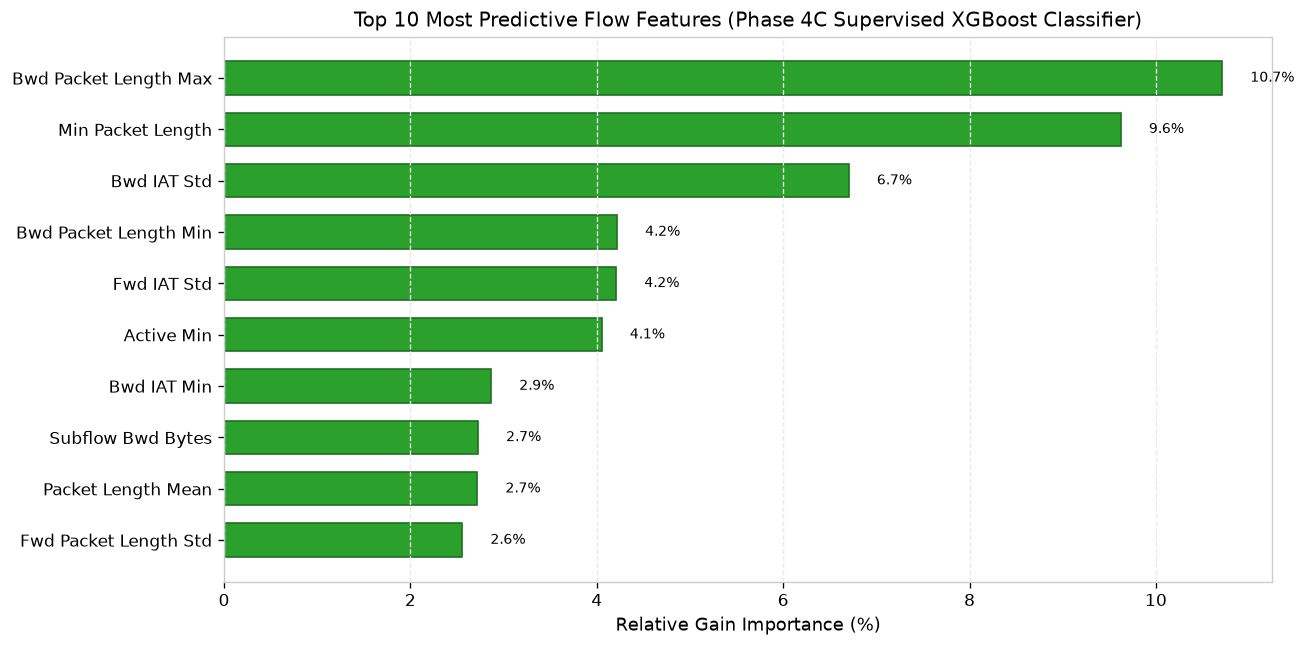

In [10]:
fig, ax = plt.subplots(figsize=(11, 5.5))

df_fi_top = df_fi.head(10).iloc[::-1]
y_pos = np.arange(len(df_fi_top))

bars = ax.barh(
    y_pos, df_fi_top["Relative Importance (%)"], color="#2ca02c", edgecolor="#1e7120", height=0.65
)
ax.set_yticks(y_pos)
ax.set_yticklabels(df_fi_top["Feature"])
ax.set_xlabel("Relative Gain Importance (%)")
ax.set_title("Top 10 Most Predictive Flow Features (Phase 4C Supervised XGBoost Classifier)")
ax.grid(True, axis="x")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.3, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()

## 6. Summary & Research Limitations

1. **Physical Feature Signatures:**
   - `Init_Win_bytes_forward` and `Bwd Packet Length Std` provide the highest discrimination for known attacks. The forward initial TCP window size reflects OS-level TCP stack configurations that differ markedly between automated attack tools (e.g. Hulk, Patator) and legitimate user browsers.
2. **Stateless Feature Limitation:**
   - While these continuous features successfully differentiate multi-packet attacks (DoS, Brute Force), they cannot distinguish single-packet TCP SYN probes without port or IP context, reinforcing the findings of Notebook 02.
